# IBM HR Analytics - Employee Attrition Preprocessing

This notebook performs data preprocessing on the IBM HR Analytics Employee Attrition dataset.

**Steps:**
1. Import Libraries
2. Load Dataset & Overview
3. Missing Values Analysis
4. Remove Constant Columns & Analyze Unique Values
5. Encode Target Variable & Visualize Class Balance
6. Encode Categorical Variables (Binary, Nominal)
7. Detect & Handle Outliers
8. Scale Numerical Features (Min-Max Normalization)
9. Final Dataset Summary & Export

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OrdinalEncoder
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid", palette="Set2", font_scale=1.2)

## Load Dataset & Overview

In [2]:
# Load Dataset - Handle quoted CSV lines and BOM encoding
import io

file_path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

# Read raw file with utf-8-sig to handle BOM
with open(file_path, 'r', encoding='utf-8-sig') as f:
    lines = f.readlines()

# Remove the enclosing quotes from each line
cleaned_lines = []
for line in lines:
    line = line.strip()
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]  # Remove first and last quote
    cleaned_lines.append(line)

# Create CSV from cleaned lines
cleaned_csv = '\n'.join(cleaned_lines)
df = pd.read_csv(io.StringIO(cleaned_csv))

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
df.info()

df.head()

DATASET OVERVIEW
Total Rows: 1470
Total Columns: 35

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## Missing Values Analysis

In [3]:
# Missing Values Analysis
print("="*60)
print("MISSING VALUES ANALYSIS")
print("="*60)

missing_values = df.isnull().sum()
missing_percent = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing %': missing_percent
})

if missing_values.sum() == 0:
    print("✓ No missing values found in the dataset!")
else:
    print(missing_df[missing_df['Missing Count'] > 0])

print(f"\nTotal missing values: {missing_values.sum()}")

MISSING VALUES ANALYSIS
✓ No missing values found in the dataset!

Total missing values: 0


## Data Cleaning: Remove Constant Columns & Analyze Unique Values

In [4]:
# Remove Constant/Useless Columns
# EmployeeCount (all=1), StandardHours (all=80), Over18 (all='Y'), EmployeeNumber (unique ID)

print("="*60)
print("REMOVING CONSTANT/USELESS COLUMNS")
print("="*60)

# Check values before dropping
print("\nColumns to remove:")
print(f"  - EmployeeCount unique values: {df['EmployeeCount'].unique()}")
print(f"  - StandardHours unique values: {df['StandardHours'].unique()}")
print(f"  - Over18 unique values: {df['Over18'].unique()}")
print(f"  - EmployeeNumber: Unique ID (not useful for prediction)")

cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df = df.drop(columns=cols_to_drop)

print(f"\n✓ Dropped {len(cols_to_drop)} columns")
print(f"Remaining columns: {df.shape[1]}")

# Unique Values Analysis
print("\n" + "="*60)
print("UNIQUE VALUES PER COLUMN")
print("="*60)

for col in df.columns:
    n_unique = df[col].nunique()
    dtype = df[col].dtype
    sample = df[col].unique()[:8]
    print(f"\n{col} ({dtype}, {n_unique} unique):")
    print(f"  {sample}")

REMOVING CONSTANT/USELESS COLUMNS

Columns to remove:
  - EmployeeCount unique values: [1]
  - StandardHours unique values: [80]
  - Over18 unique values: <StringArray>
['Y']
Length: 1, dtype: str
  - EmployeeNumber: Unique ID (not useful for prediction)

✓ Dropped 4 columns
Remaining columns: 31

UNIQUE VALUES PER COLUMN

Age (int64, 43 unique):
  [41 49 37 33 27 32 59 30]

Attrition (str, 2 unique):
  <StringArray>
['Yes', 'No']
Length: 2, dtype: str

BusinessTravel (str, 3 unique):
  <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str

DailyRate (int64, 886 unique):
  [1102  279 1373 1392  591 1005 1324 1358]

Department (str, 3 unique):
  <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str

DistanceFromHome (int64, 29 unique):
  [ 1  8  2  3 24 23 27 16]

Education (int64, 5 unique):
  [2 1 4 3 5]

EducationField (str, 6 unique):
  <StringArray>
[   'Life Sciences',            'Other',          'Medical',
 

## Encode Target Variable & Visualize Class Balance

TARGET VARIABLE ENCODING

Original Attrition values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Encoded Attrition values: [1 0]

CLASS BALANCE

No (0): 1233 (83.9%)
Yes (1): 237 (16.1%)


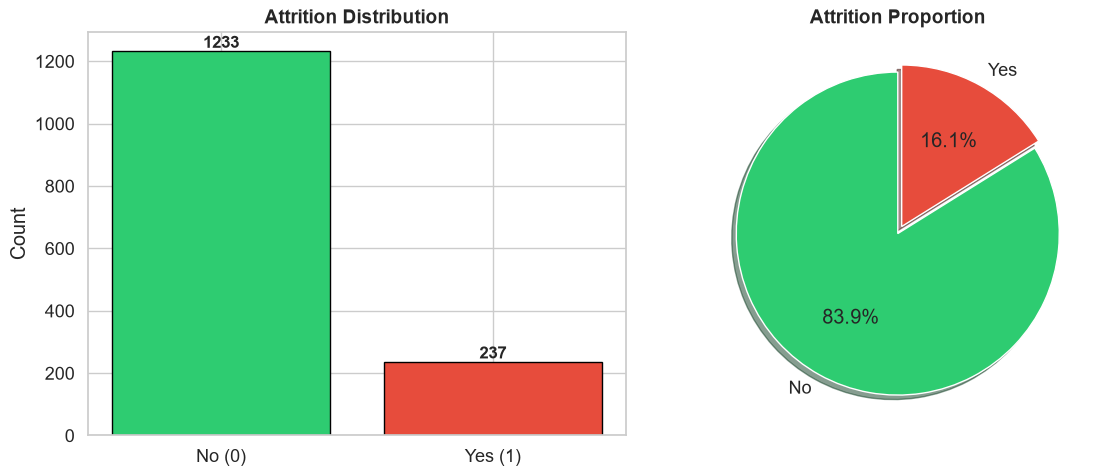

In [5]:
# Encode Target Variable (Attrition: Yes=1, No=0)
print("="*60)
print("TARGET VARIABLE ENCODING")
print("="*60)

print(f"\nOriginal Attrition values: {df['Attrition'].unique()}")
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})
print(f"Encoded Attrition values: {df['Attrition'].unique()}")

# Class Balance Visualization
print("\n" + "="*60)
print("CLASS BALANCE")
print("="*60)

attrition_counts = df['Attrition'].value_counts()
print(f"\nNo (0): {attrition_counts[0]} ({attrition_counts[0]/len(df)*100:.1f}%)")
print(f"Yes (1): {attrition_counts[1]} ({attrition_counts[1]/len(df)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
ax1 = axes[0]
colors = ['#2ecc71', '#e74c3c']
bars = ax1.bar(['No (0)', 'Yes (1)'], attrition_counts.values, color=colors, edgecolor='black')
ax1.set_title('Attrition Distribution', fontsize=14, fontweight='bold')
ax1.set_ylabel('Count')
for bar, count in zip(bars, attrition_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
             f'{count}', ha='center', fontsize=12, fontweight='bold')

# Pie chart
ax2 = axes[1]
ax2.pie(attrition_counts.values, labels=['No', 'Yes'], autopct='%1.1f%%', 
        colors=colors, explode=(0, 0.05), startangle=90, shadow=True)
ax2.set_title('Attrition Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# Train-Test Split
import random
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("="*60)
print("TRAIN-TEST SPLIT")
print("="*60)

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print("\nTrain target distribution:")
print(f"  - 0 (No): {(y_train==0).sum()}")
print(f"  - 1 (Yes): {(y_train==1).sum()}")
print("\nTest target distribution:")
print(f"  - 0 (No): {(y_test==0).sum()}")
print(f"  - 1 (Yes): {(y_test==1).sum()}")


TRAIN-TEST SPLIT

Train shape: (1176, 30)
Test shape: (294, 30)

Train target distribution:
  - 0 (No): 986
  - 1 (Yes): 190

Test target distribution:
  - 0 (No): 247
  - 1 (Yes): 47


In [7]:
# Encode Categorical Variables on Train Set
print("="*60)
print("ENCODING CATEGORICAL VARIABLES (TRAIN SET)")
print("="*60)

# Binary columns are label-encoded. Nominal columns are first integer-coded,
# then smoothed target-encoded before the numeric SMOTE step.
print("\n--- Binary Variables (Label Encoding) ---")
binary_cols = ['Gender', 'OverTime']
binary_encoders = {}

for col in binary_cols:
    print(f"\n{col}: {X_train[col].unique()}")
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    binary_encoders[col] = le
    print(f"  -> Encoded: {X_train[col].unique()}")

print("\n--- Nominal Variables (Integer Coding Before Target Encoding) ---")
nominal_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']
ordinal_cols = [
    'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance'
]
ordinal_cols = [col for col in ordinal_cols if col in X_train.columns]

ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train[nominal_cols] = ordinal_encoder.fit_transform(X_train[nominal_cols].astype(str)).astype(int)
X_test[nominal_cols] = ordinal_encoder.transform(X_test[nominal_cols].astype(str)).astype(int)

print(f"  -> Integer-coded nominal columns: {nominal_cols}")
print("\n✓ Categorical values are numeric before plain SMOTE")


ENCODING CATEGORICAL VARIABLES (TRAIN SET)

--- Binary Variables (Label Encoding) ---

Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
  -> Encoded: [0 1]

OverTime: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
  -> Encoded: [0 1]

--- Nominal Variables (Integer Coding Before Target Encoding) ---
  -> Integer-coded nominal columns: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']

✓ Categorical values are numeric before plain SMOTE


OUTLIER DETECTION (Z-SCORE METHOD, TRAIN SET ONLY)
Outliers detected in training partition: 70 rows (5.95%)
Outliers are retained; this cell only reports and visualises them.


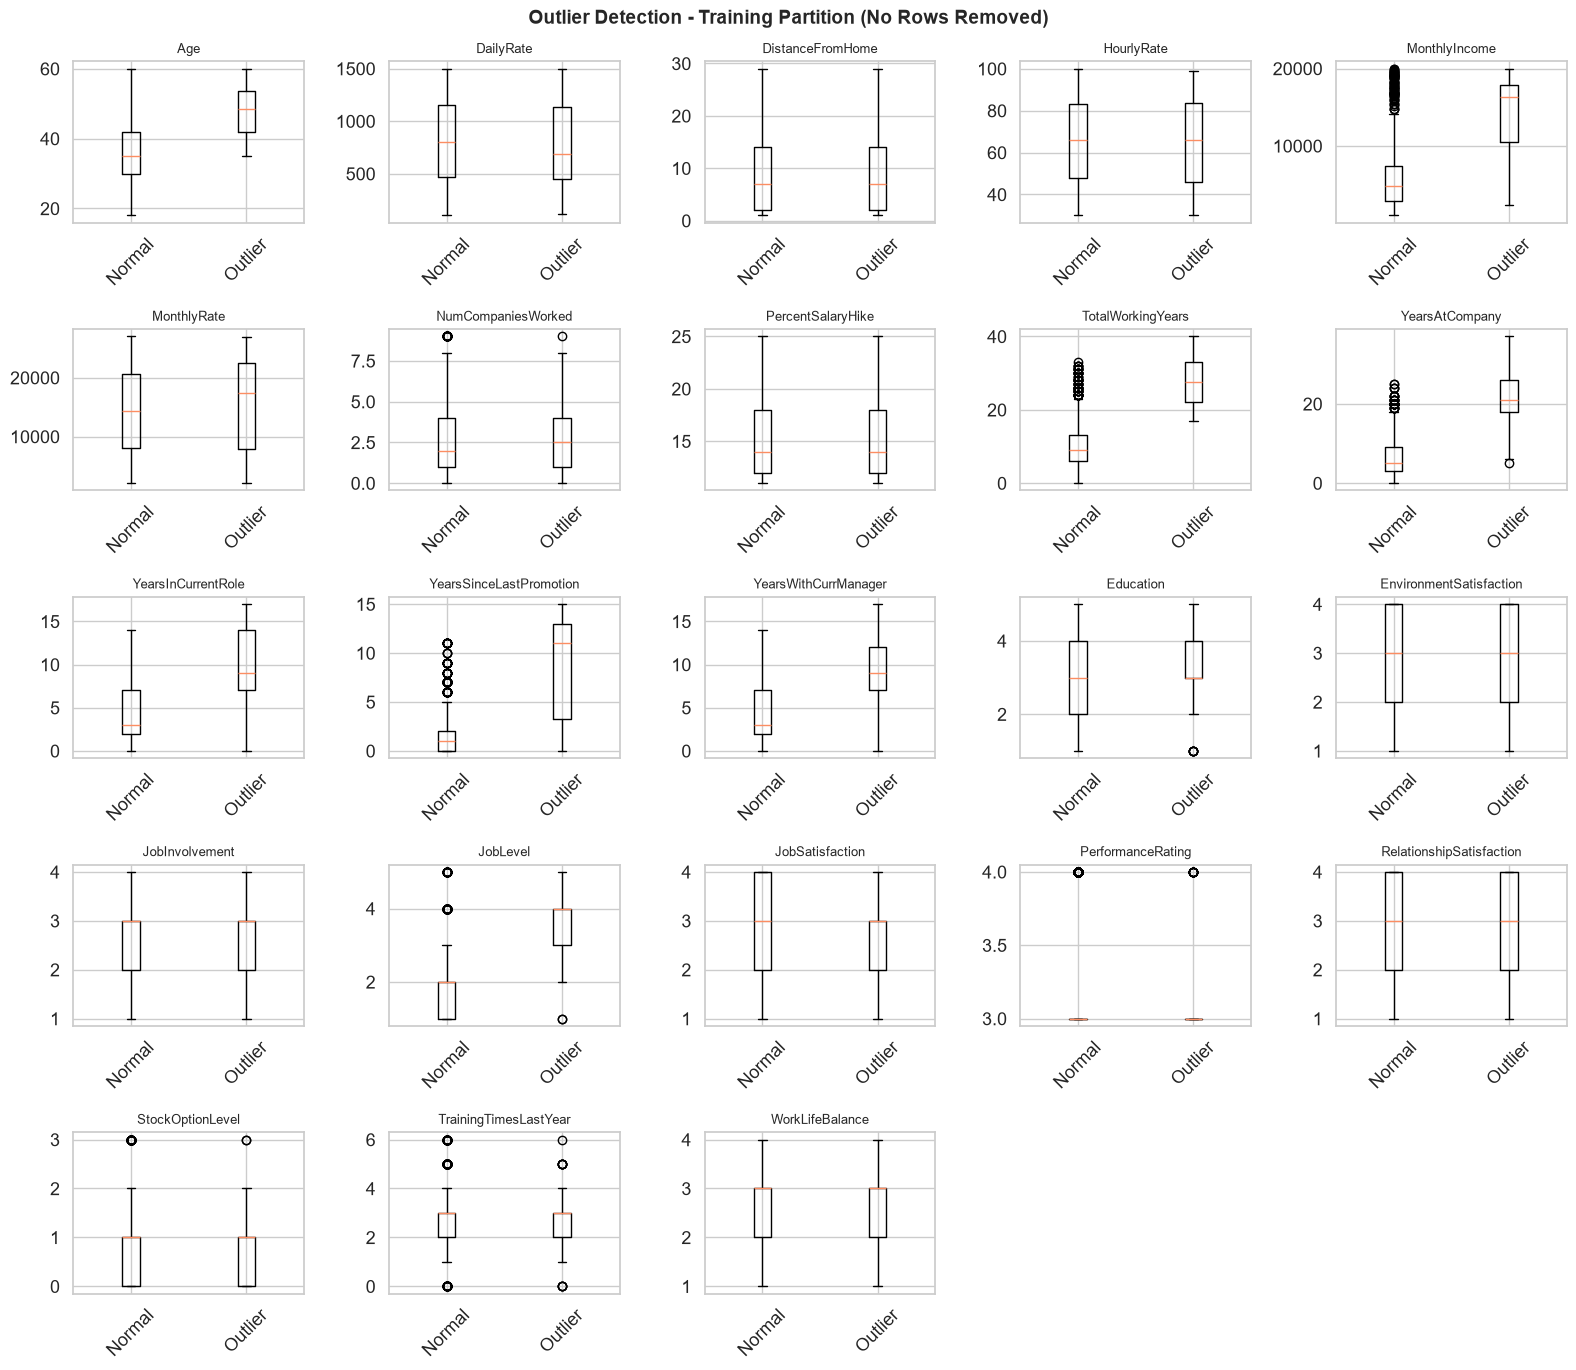

In [8]:
# Outlier Detection using Z-Score Method (Train Set Only) - Visualization Only
from scipy.stats import zscore
import matplotlib.pyplot as plt

print("="*60)
print("OUTLIER DETECTION (Z-SCORE METHOD, TRAIN SET ONLY)")
print("="*60)

numerical_cols = [
    'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
    'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole',
    'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Education',
    'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'TrainingTimesLastYear', 'WorkLifeBalance'
]
numerical_cols = [col for col in numerical_cols if col in X_train.columns]

z_scores = pd.DataFrame(
    zscore(X_train[numerical_cols], nan_policy='omit'),
    index=X_train.index,
    columns=numerical_cols,
)
outlier_mask = z_scores.abs().gt(3).any(axis=1)
print(f"Outliers detected in training partition: {outlier_mask.sum()} rows ({outlier_mask.mean()*100:.2f}%)")
print("Outliers are retained; this cell only reports and visualises them.")

fig, axes = plt.subplots(5, 5, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    axes[i].boxplot([X_train.loc[~outlier_mask, col], X_train.loc[outlier_mask, col]], tick_labels=['Normal', 'Outlier'])
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(axis='x', labelrotation=45)
for axis in axes[len(numerical_cols):]:
    axis.axis('off')
plt.suptitle('Outlier Detection - Training Partition (No Rows Removed)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [9]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

print("="*60)
print("TARGET ENCODING AND NUMERIC PREPARATION")
print("="*60)

# Preserve the train-only, ordinal-coded feature matrix for fold-wise pipelines.
# The model pipelines below fit this target encoder inside each CV fold.
X_train_raw_model = X_train.copy()
X_test_raw_model = X_test.copy()

class MEstimateTargetEncoder(BaseEstimator, TransformerMixin):
    """Fold-safe smoothed target encoding for already ordinal-coded columns."""

    def __init__(self, columns=None, m=10):
        self.columns = columns
        self.m = m

    def fit(self, X, y):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.feature_names_in_ = list(X_df.columns)
        self.global_mean_ = float(np.asarray(y).mean())
        self.maps_ = {}
        columns = self.columns if self.columns is not None else self.feature_names_in_
        for col in columns:
            if col not in X_df.columns:
                continue
            temp = pd.DataFrame({"value": X_df[col], "target": np.asarray(y)})
            stats = temp.groupby("value")["target"].agg(["mean", "count"])
            stats["estimate"] = (
                stats["count"] * stats["mean"] + self.m * self.global_mean_
            ) / (stats["count"] + self.m)
            self.maps_[col] = stats["estimate"].to_dict()
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        X_df = X_df.copy()
        for col, mapping in self.maps_.items():
            if col in X_df.columns:
                X_df[col] = X_df[col].map(mapping).fillna(self.global_mean_)
        return X_df

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


def m_estimator_target_encode_fit(X_train_local, y_train_local, col, m=10):
    encoder = MEstimateTargetEncoder(columns=[col], m=m)
    encoder.fit(X_train_local[[col]], y_train_local)
    return encoder.maps_.get(col, {}), encoder.global_mean_


def m_estimator_target_encode_transform(X_local, col, encoding_map, global_mean):
    return X_local[col].map(encoding_map).fillna(global_mean)


nominal_encoders = {}
m_value = 10
print(f"\nApplying M-Estimator Target Encoding (m={m_value}) on the full training partition for export...")
print(f"Global target mean (train): {y_train.mean():.4f}\n")

for col in nominal_cols:
    encoding_map, global_mean = m_estimator_target_encode_fit(X_train, y_train, col, m=m_value)
    nominal_encoders[col] = (encoding_map, global_mean)
    X_train[col] = m_estimator_target_encode_transform(X_train, col, encoding_map, global_mean)
    X_test[col] = m_estimator_target_encode_transform(X_test, col, encoding_map, global_mean)
    print(f"  {col}: {len(encoding_map)} categories encoded")

print("\n✓ Export/feature-ranking matrix prepared from the training partition")


TARGET ENCODING AND NUMERIC PREPARATION

Applying M-Estimator Target Encoding (m=10) on the full training partition for export...
Global target mean (train): 0.1616

  BusinessTravel: 3 categories encoded
  Department: 3 categories encoded
  EducationField: 6 categories encoded
  JobRole: 9 categories encoded
  MaritalStatus: 3 categories encoded

✓ Export/feature-ranking matrix prepared from the training partition


In [10]:
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

print("\n" + "="*60)
print("STANDARD SCALING AND SMOTE")
print("="*60)

# This notebook uses ordinary SMOTE on the fully numeric, target-encoded matrix.
# Categorical columns have already been converted to numbers before resampling.
numeric_columns = list(X_train.columns)
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("✓ StandardScaler fitted on the original training partition")
print("✓ Plain SMOTE applied only to the training partition")
print(f"  Original train shape: {X_train.shape}")
print(f"  SMOTE train shape: {X_train_smote.shape}")
print(f"  Class distribution after SMOTE: {np.bincount(y_train_smote)}")



STANDARD SCALING AND SMOTE
✓ StandardScaler fitted on the original training partition
✓ Plain SMOTE applied only to the training partition
  Original train shape: (1176, 30)
  SMOTE train shape: (1972, 30)
  Class distribution after SMOTE: [986 986]


## Balance Train Set with SMOTE

## Scale Numerical Features (Min-Max Normalization) - Train & Test

## Outlier Detection (Train Set) - Visualization Only

## Encode Categorical Variables (Train Set)

Test Set Class Distribution:
Class 0: 247 (84.01%)
Class 1: 47 (15.99%)


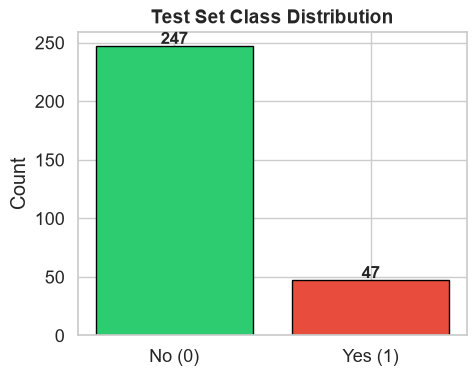

In [11]:
# Display class distribution for the test set
test_counts = y_test.value_counts()
print("Test Set Class Distribution:")
for label, count in test_counts.items():
    print(f"Class {label}: {count} ({count/len(y_test)*100:.2f}%)")

import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
colors = ['#2ecc71', '#e74c3c']
plt.bar(['No (0)', 'Yes (1)'], [test_counts.get(0,0), test_counts.get(1,0)], color=colors, edgecolor='black')
plt.title('Test Set Class Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
for i, count in enumerate([test_counts.get(0,0), test_counts.get(1,0)]):
    plt.text(i, count + 2, f'{count}', ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Final Dataset Preprocessing Summary & Export

In [12]:
# Final Dataset Summary & Export
print("="*60)
print("FINAL PREPROCESSING SUMMARY")
print("="*60)

print(f"\nTrain Set (SMOTE applied):")
print(f"  Shape: {X_train_smote.shape}")
print(f"  Class 0 (No): {(y_train_smote==0).sum()}")
print(f"  Class 1 (Yes): {(y_train_smote==1).sum()}")

print(f"\nTest Set (Original, No SMOTE):")
print(f"  Shape: {X_test.shape}")
print(f"  Class 0 (No): {(y_test==0).sum()}")
print(f"  Class 1 (Yes): {(y_test==1).sum()}")

print("\n" + "="*60)
print("COLUMN CATEGORIES")
print("="*60)

# Categorize final columns
binary = ['Gender', 'OverTime']
ordinal = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 
           'JobLevel', 'JobSatisfaction', 'PerformanceRating',
           'RelationshipSatisfaction', 'StockOptionLevel', 
           'TrainingTimesLastYear', 'WorkLifeBalance']
numerical = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 
             'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
             'PercentSalaryHike', 'TotalWorkingYears', 'YearsAtCompany',
             'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
nominal = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']

print(f"\nBinary: {len(binary)} columns")
print(f"Ordinal: {len(ordinal)} columns")
print(f"Numerical: {len(numerical)} columns")
print(f"Target Encoded (Nominal): {len(nominal)} columns")
print(f"Total Features: {X_train_smote.shape[1]} columns")

# Export datasets
print("\n" + "="*60)
print("EXPORTING DATASETS")
print("="*60)

# Combine train SMOTE with target
train_smote_df = pd.DataFrame(X_train_smote, columns=X_train.columns)
train_smote_df['Attrition'] = y_train_smote.values
output_file_train = 'ibm_train_balanced_smote.csv'
train_smote_df.to_csv(output_file_train, index=False)
print(f"✓ Train set (SMOTE) saved to: {output_file_train}")

# Combine test with target
test_df = pd.DataFrame(X_test, columns=X_test.columns)
test_df['Attrition'] = y_test.values
output_file_test = 'ibm_test.csv'
test_df.to_csv(output_file_test, index=False)
print(f"✓ Test set saved to: {output_file_test}")

# Preview
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
print("\nTrain Set (SMOTE) Preview:")
display(train_smote_df.head())
print("\nTest Set Preview:")
display(test_df.head())


FINAL PREPROCESSING SUMMARY

Train Set (SMOTE applied):
  Shape: (1972, 30)
  Class 0 (No): 986
  Class 1 (Yes): 986

Test Set (Original, No SMOTE):
  Shape: (294, 30)
  Class 0 (No): 247
  Class 1 (Yes): 47

COLUMN CATEGORIES

Binary: 2 columns
Ordinal: 10 columns
Numerical: 13 columns
Target Encoded (Nominal): 5 columns
Total Features: 30 columns

EXPORTING DATASETS
✓ Train set (SMOTE) saved to: ibm_train_balanced_smote.csv
✓ Test set saved to: ibm_test.csv

Train Set (SMOTE) Preview:


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,1.090194,-0.245733,1.049455,1.385821,-0.899915,1.064209,-0.111947,-0.658710,-1.221280,-0.908436,1.795282,1.762189,-1.022588,-0.647997,-0.797106,2.026752,0.931289,1.330763,-0.637729,-0.337129,-0.432065,0.240218,2.613100,2.261482,-0.605389,0.337621,-0.665706,-0.625365,-0.368024,-0.616406,0
1,-1.634828,-0.245733,-0.523449,-0.733727,-0.899915,-1.855332,1.479269,0.260202,0.818813,1.694111,0.373564,-0.986265,1.163522,1.153526,-0.622953,-0.864408,0.682742,-1.083704,-0.637729,-0.337129,-0.432065,0.240218,0.247430,-1.072675,-0.605389,0.337621,-0.830071,-0.905635,-0.056884,-0.897047,0
2,0.981193,-0.245733,-0.992080,1.385821,-0.777610,-1.855332,1.470315,-1.577622,0.818813,-0.662913,0.373564,1.762189,-1.022588,0.252765,-0.622953,2.347706,0.167705,0.123529,-0.637729,-0.880974,-0.432065,1.160403,0.247430,1.492061,0.190962,0.337621,0.813578,1.336527,0.565398,1.348076,0
3,-1.307825,-0.245733,-0.453653,1.385821,0.445433,-1.855332,-0.715715,-0.658710,0.818813,-1.252169,0.373564,-0.986265,2.463590,0.252765,-0.622953,-0.956202,1.667056,-0.681293,-0.637729,-1.152896,-0.432065,0.240218,-0.935405,-0.559727,-1.401740,0.337621,-0.008246,-0.064824,-0.679165,0.506155,0
4,0.654191,1.842426,0.491086,-0.733727,-0.043784,2.037390,-0.715715,1.179114,0.818813,0.319180,0.373564,-0.070114,1.163522,0.252765,-0.797106,-0.185956,0.728362,0.123529,1.568064,-0.609051,-0.432065,-0.679966,0.247430,-0.175017,0.190962,0.337621,0.156119,0.775986,0.565398,0.786795,0



Test Set Preview:


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
1061,-1.416826,-1.716092,0.064832,1.385821,0.445433,-0.882152,-0.111947,1.179114,-1.221280,0.613808,0.373564,-0.986265,2.463590,-0.647997,-0.622953,-0.969745,-1.013556,-0.681293,-0.637729,-0.609051,-0.432065,0.240218,0.247430,-1.329148,-0.605389,0.337621,-0.994436,-1.185905,-0.679165,-1.177687,0
891,0.763191,-0.245733,0.780241,-0.733727,-0.899915,-1.855332,-0.111947,-1.577622,-1.221280,0.319180,1.795282,-0.986265,-0.323570,1.153526,-0.622953,-0.974474,0.777738,-0.681293,-0.637729,-0.609051,-0.432065,1.160403,0.247430,-0.175017,1.783664,0.337621,0.484849,0.215446,1.498820,0.786795,0
456,-0.653820,-0.245733,-0.289134,1.385821,-0.288393,0.091029,-0.111947,0.260202,0.818813,-1.055750,-1.048155,0.846038,-1.022588,1.153526,-0.797106,1.077650,1.516147,2.537997,-0.637729,1.566330,2.314467,0.240218,0.247430,-0.175017,0.190962,-1.055510,-0.336976,-0.064824,-0.679165,-0.897047,0
922,0.763191,-0.245733,0.984644,-0.733727,-0.655306,-0.882152,-0.111947,0.260202,0.818813,1.301274,1.795282,2.678340,-1.022588,-1.548758,-0.797106,2.718533,0.429326,-0.681293,-0.637729,-0.337129,-0.432065,1.160403,1.430265,1.876772,0.987313,-1.055510,2.950322,1.336527,3.676804,2.470637,0
69,-0.108815,-0.245733,-1.211439,-0.733727,-0.043784,0.091029,-0.715715,1.179114,0.818813,0.662913,-1.048155,-0.986265,-0.323570,0.252765,-0.622953,-0.678457,1.027398,-1.083704,1.568064,0.478639,-0.432065,-1.600151,0.247430,-1.200911,-2.198092,-1.055510,-0.994436,-1.185905,-0.679165,-1.177687,1


In [13]:
import numpy as np
from skrebate import ReliefF, MultiSURF

print("="*60)
print("FEATURE SELECTION - ReliefF AND MultiSURF")
print("="*60)

# Ranking is fitted once on the training partition only. The held-out test set is
# never used for ranking. CV below is used to select the smallest useful top-N subset.
feature_names = X_train.columns.tolist()
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train)

print(f"\nFeature matrix for ranking: {X_train.shape}")
print(f"Target distribution used for ranking: No={sum(y_train==0)}, Yes={sum(y_train==1)}")


FEATURE SELECTION - ReliefF AND MultiSURF

Feature matrix for ranking: (1176, 30)
Target distribution used for ranking: No=986, Yes=190


In [14]:
print("ReliefF Feature Ranking")
print("-"*60)

relieff = ReliefF(n_features_to_select=X_train_np.shape[1], n_neighbors=100)
relieff.fit(X_train_np, y_train_np)
relieff_scores_dict = dict(zip(feature_names, relieff.feature_importances_))
relieff_sorted = sorted(relieff_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by ReliefF Score:")
for i, (feat, score) in enumerate(relieff_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


ReliefF Feature Ranking
------------------------------------------------------------

All Features Ranked by ReliefF Score:
   1. OverTime: 0.1474
   2. JobRole: 0.1436
   3. JobLevel: 0.1395
   4. MaritalStatus: 0.1257
   5. Department: 0.1231
   6. StockOptionLevel: 0.1116
   7. WorkLifeBalance: 0.1009
   8. EducationField: 0.0941
   9. EnvironmentSatisfaction: 0.0892
  10. JobSatisfaction: 0.0848
  11. JobInvolvement: 0.0783
  12. RelationshipSatisfaction: 0.0772
  13. Age: 0.0721
  14. TotalWorkingYears: 0.0704
  15. MonthlyIncome: 0.0703
  16. TrainingTimesLastYear: 0.0657
  17. Gender: 0.0648
  18. BusinessTravel: 0.0629
  19. Education: 0.0626
  20. NumCompaniesWorked: 0.0543
  21. YearsAtCompany: 0.0430
  22. DistanceFromHome: 0.0340
  23. YearsWithCurrManager: 0.0329
  24. YearsInCurrentRole: 0.0319
  25. PerformanceRating: 0.0319
  26. PercentSalaryHike: 0.0287
  27. DailyRate: 0.0222
  28. HourlyRate: 0.0148
  29. MonthlyRate: 0.0139
  30. YearsSinceLastPromotion: 0.0117


In [15]:
print("MultiSURF Feature Ranking")
print("-"*60)

multisurf = MultiSURF(n_features_to_select=X_train_np.shape[1])
multisurf.fit(X_train_np, y_train_np)
multisurf_scores_dict = dict(zip(feature_names, multisurf.feature_importances_))
multisurf_sorted = sorted(multisurf_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by MultiSURF Score:")
for i, (feat, score) in enumerate(multisurf_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


MultiSURF Feature Ranking
------------------------------------------------------------

All Features Ranked by MultiSURF Score:
   1. OverTime: 0.0781
   2. Age: 0.0414
   3. WorkLifeBalance: 0.0317
   4. TotalWorkingYears: 0.0230
   5. JobLevel: 0.0176
   6. DistanceFromHome: 0.0152
   7. YearsAtCompany: 0.0097
   8. StockOptionLevel: 0.0064
   9. MaritalStatus: 0.0058
  10. MonthlyIncome: 0.0051
  11. DailyRate: 0.0031
  12. EnvironmentSatisfaction: 0.0029
  13. BusinessTravel: 0.0017
  14. JobInvolvement: 0.0011
  15. YearsWithCurrManager: 0.0004
  16. JobSatisfaction: -0.0002
  17. JobRole: -0.0004
  18. HourlyRate: -0.0022
  19. MonthlyRate: -0.0031
  20. YearsInCurrentRole: -0.0034
  21. Department: -0.0048
  22. NumCompaniesWorked: -0.0049
  23. PercentSalaryHike: -0.0049
  24. TrainingTimesLastYear: -0.0052
  25. YearsSinceLastPromotion: -0.0055
  26. RelationshipSatisfaction: -0.0069
  27. EducationField: -0.0095
  28. PerformanceRating: -0.0120
  29. Gender: -0.0120
  30. Edu

In [16]:
# Export Feature Rankings to Excel (Original Feature Order)
import pandas as pd

# Create DataFrame with original feature order
feature_ranking_df = pd.DataFrame({
    'Feature': feature_names,
    'ReliefF_Score': [relieff_scores_dict[f] for f in feature_names],
    'MultiSURF_Score': [multisurf_scores_dict[f] for f in feature_names]
})

# Add ranking columns (1=best, higher numbers=lower rank)
feature_ranking_df['ReliefF_Rank'] = feature_ranking_df['ReliefF_Score'].rank(ascending=False, method='min').astype(int)
feature_ranking_df['MultiSURF_Rank'] = feature_ranking_df['MultiSURF_Score'].rank(ascending=False, method='min').astype(int)

# Export to Excel
export_filename = 'ibm_feature_rankings.xlsx'
feature_ranking_df.to_excel(export_filename, index=False, sheet_name='Feature Rankings')

print(f"✓ Feature rankings exported to: {export_filename}")
print(f"✓ Total features: {len(feature_ranking_df)}")
print(f"\nPreview (first 5 features in original order):")
print(feature_ranking_df.head())


✓ Feature rankings exported to: ibm_feature_rankings.xlsx
✓ Total features: 30

Preview (first 5 features in original order):
            Feature  ReliefF_Score  MultiSURF_Score  ReliefF_Rank  MultiSURF_Rank
0               Age       0.072121         0.041380            13               2
1    BusinessTravel       0.062866         0.001685            18              13
2         DailyRate       0.022207         0.003130            27              11
3        Department       0.123146        -0.004799             5              21
4  DistanceFromHome       0.034024         0.015221            22               6


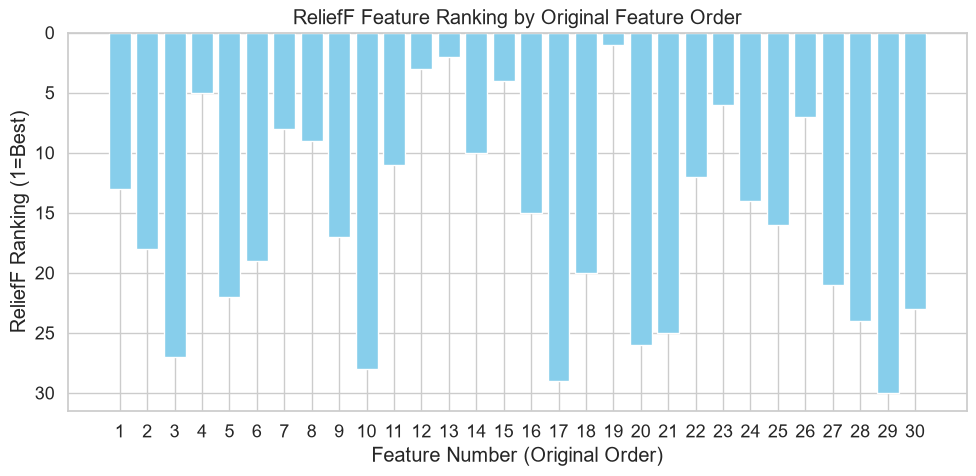

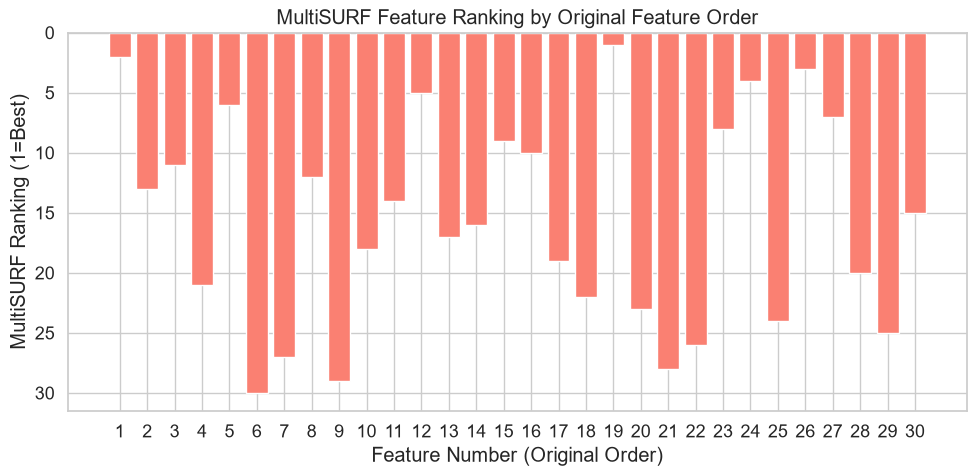

In [17]:
# Visualization: Feature Ranking (Y=Ranking, X=Feature Number, Original Order)
import matplotlib.pyplot as plt
import numpy as np

# Get feature names in original order
feature_numbers = np.arange(1, len(feature_names)+1)

# ReliefF: get ranking for each feature in original order
relieff_ranking = [
    [feat for feat, _ in relieff_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, relieff_ranking, color='skyblue')
plt.ylabel('ReliefF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('ReliefF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()  # 1 is best, so invert
plt.tight_layout()
plt.show()

# MultiSURF: get ranking for each feature in original order
multisurf_ranking = [
    [feat for feat, _ in multisurf_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, multisurf_ranking, color='salmon')
plt.ylabel('MultiSURF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('MultiSURF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

  

In [18]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("="*60)
print("F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM")
print("="*60)

scoring_metric = "f1"
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.1, 0.3],
    "subsample": [0.8, 1.0],
}
svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"],
}
dt_param_grid = {
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

def prefix_grid(grid, prefix="clf"):
    return {f"{prefix}__{k}": v for k, v in grid.items()}

def build_model_pipeline(estimator, use_smote=True, smote_seed=None):
    steps = [
        ("target_encode", MEstimateTargetEncoder(columns=nominal_cols, m=m_value)),
        ("scale", StandardScaler()),
    ]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED if smote_seed is None else smote_seed)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

def tune_model(estimator, grid):
    pipeline = build_model_pipeline(estimator)
    search = GridSearchCV(
        pipeline,
        prefix_grid(grid),
        cv=cv_splitter,
        scoring=scoring_metric,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train_raw_model, y_train)
    print(f"{estimator.__class__.__name__} best CV F1: {search.best_score_:.4f}")
    print(f"  best parameters: {search.best_params_}")
    return search

gs_rf = tune_model(RandomForestClassifier(random_state=SEED), rf_param_grid)
gs_xgb = tune_model(XGBClassifier(random_state=SEED, eval_metric="logloss"), xgb_param_grid)
gs_svm = tune_model(SVC(probability=True, random_state=SEED), svm_param_grid)
gs_dt = tune_model(DecisionTreeClassifier(random_state=SEED), dt_param_grid)
gs_gb = tune_model(GradientBoostingClassifier(random_state=SEED), gb_param_grid)

# Use the tuned classifier settings as the voting components. Preprocessing and
# SMOTE are applied by build_model_pipeline inside each CV fold.
rf = clone(gs_rf.best_estimator_.named_steps["clf"])
xgb = clone(gs_xgb.best_estimator_.named_steps["clf"])
svm = clone(gs_svm.best_estimator_.named_steps["clf"])
dt = clone(gs_dt.best_estimator_.named_steps["clf"])
gb = clone(gs_gb.best_estimator_.named_steps["clf"])

voting_clf = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="soft",
)
voting_clf_hard = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="hard",
)

# Every voting combination is evaluated and optimized independently. The
# additional combinations are shown in tables but are not added to the main
# top-N figure.
voting_models = {
    "General Voting": voting_clf,
    "Hard Voting": voting_clf_hard,
    "Voting GB + XGBoost (equal weights)": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting RF + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting GB + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))],
        voting="soft",
    ),
}

cv_models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
cv_models.update(voting_models)

cv_results = []
for name, estimator in cv_models.items():
    scores = cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_train_raw_model,
        y_train,
        cv=cv_splitter,
        scoring="f1",
        n_jobs=-1,
    )
    cv_results.append({"Model": name, "Mean CV F1": scores.mean(), "Std CV F1": scores.std()})
    print(f"{name}: mean CV F1={scores.mean():.4f}, std={scores.std():.4f}")

cv_results = pd.DataFrame(cv_results)
display(cv_results.sort_values("Mean CV F1", ascending=False).round(4))

def positive_scores(fitted_model, X):
    """Return a continuous positive-class score for ROC/PR metrics."""
    try:
        return fitted_model.predict_proba(X)[:, 1]
    except (AttributeError, NotImplementedError):
        if hasattr(fitted_model, "decision_function"):
            return fitted_model.decision_function(X)
        return fitted_model.predict(X)

def run_to_run_variance(estimator, X_features, y_target, model_name, seeds=(SEED, SEED + 1, SEED + 2)):
    """Evaluate CV-F1 stability across seeds for a fixed feature subset."""
    rows = []
    for run_seed in seeds:
        run_estimator = clone(estimator)
        seed_params = {
            name: run_seed
            for name in run_estimator.get_params(deep=True)
            if name.endswith("random_state")
        }
        if seed_params:
            run_estimator.set_params(**seed_params)
        run_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run_seed)
        run_scores = cross_val_score(
            build_model_pipeline(run_estimator, smote_seed=run_seed),
            X_features,
            y_target,
            cv=run_cv,
            scoring="f1",
            n_jobs=-1,
        )
        rows.append({"Model": model_name, "Seed": run_seed, "Mean CV F1": run_scores.mean(), "Fold SD": run_scores.std()})
    return pd.DataFrame(rows)


F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM
RandomForestClassifier best CV F1: 0.5310
  best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
XGBClassifier best CV F1: 0.5420
  best parameters: {'clf__learning_rate': 0.3, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 0.8}
SVC best CV F1: 0.5200
  best parameters: {'clf__C': 0.1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
DecisionTreeClassifier best CV F1: 0.3965
  best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5}
GradientBoostingClassifier best CV F1: 0.5355
  best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 0.8}
Random Forest: mean CV F1=0.5310, std=0.1138
XGBoost: mean CV F1=0.5420, std=0.0750
SVM: mean CV F1=0.5200, std=0.0167
Decision Tree: mean CV F1=0.3965, std=0.0443
Gradient Boosting: mean CV F1=0.5355, std=0.0890
General 

,Model,Mean CV F1,Std CV F1
8,Voting RF + XGBoost,0.5658,0.0783
10,Voting GB + XGBoost + SVM,0.5470,0.0600
11,Voting RF + GB + XGBoost,0.5468,0.0587
7,Voting GB + XGBoost (equal weights),0.5464,0.0638
9,Voting GB + SVM,0.5459,0.0578
12,Voting All Five,0.5445,0.0388
1,XGBoost,0.5420,0.0750
4,Gradient Boosting,0.5355,0.0890
0,Random Forest,0.5310,0.1138
2,SVM,0.5200,0.0167


In [19]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

print("="*60)
print("TOP-N FEATURE CURVES USING F1 - IBM")
print("="*60)

max_n = len(feature_names)
cv_folds = cv_splitter
scoring = "f1"

base_model_templates = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
model_templates = {**base_model_templates, **voting_models}

def evaluate_top_n(selected_features, estimator):
    X_subset = X_train_raw_model.loc[:, selected_features]
    return cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_subset,
        y_train,
        cv=cv_folds,
        scoring=scoring,
        n_jobs=-1,
    ).mean()

scores = {
    "relief": {name: [] for name in model_templates},
    "multi": {name: [] for name in model_templates},
}

for n in range(1, max_n + 1):
    relief_features = [feature for feature, _ in relieff_sorted[:n]]
    multi_features = [feature for feature, _ in multisurf_sorted[:n]]
    for name, estimator in model_templates.items():
        scores["relief"][name].append(evaluate_top_n(relief_features, estimator))
        scores["multi"][name].append(evaluate_top_n(multi_features, estimator))

# Preserve the existing variables used by the base-model plot. All remaining
# voting models are optimized above and reported in a separate table.
rf_acc_relief = scores["relief"]["Random Forest"]
xgb_acc_relief = scores["relief"]["XGBoost"]
svm_acc_relief = scores["relief"]["SVM"]
dt_acc_relief = scores["relief"]["Decision Tree"]
gb_acc_relief = scores["relief"]["Gradient Boosting"]
voting_clf_acc_relief = scores["relief"]["General Voting"]
voting_clf_hard_acc_relief = scores["relief"]["Hard Voting"]
rf_acc_multi = scores["multi"]["Random Forest"]
xgb_acc_multi = scores["multi"]["XGBoost"]
svm_acc_multi = scores["multi"]["SVM"]
dt_acc_multi = scores["multi"]["Decision Tree"]
gb_acc_multi = scores["multi"]["Gradient Boosting"]
voting_clf_acc_multi = scores["multi"]["General Voting"]
voting_clf_hard_acc_multi = scores["multi"]["Hard Voting"]

def first_argmax(values):
    maximum = max(values)
    return next(i + 1 for i, value in enumerate(values) if value >= maximum)

best_feature_counts = {
    selector_name: {
        model_name: first_argmax(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_cv_f1 = {
    selector_name: {
        model_name: max(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

# Compatibility aliases for the base-model reporting cells.
best_rf_relief = best_feature_counts["ReliefF"]["Random Forest"]
best_xgb_relief = best_feature_counts["ReliefF"]["XGBoost"]
best_svm_relief = best_feature_counts["ReliefF"]["SVM"]
best_dt_relief = best_feature_counts["ReliefF"]["Decision Tree"]
best_gb_relief = best_feature_counts["ReliefF"]["Gradient Boosting"]
best_voting_relief = best_feature_counts["ReliefF"]["General Voting"]
best_voting_hard_relief = best_feature_counts["ReliefF"]["Hard Voting"]
best_rf_multi = best_feature_counts["MultiSURF"]["Random Forest"]
best_xgb_multi = best_feature_counts["MultiSURF"]["XGBoost"]
best_svm_multi = best_feature_counts["MultiSURF"]["SVM"]
best_dt_multi = best_feature_counts["MultiSURF"]["Decision Tree"]
best_gb_multi = best_feature_counts["MultiSURF"]["Gradient Boosting"]
best_voting_multi = best_feature_counts["MultiSURF"]["General Voting"]
best_voting_hard_multi = best_feature_counts["MultiSURF"]["Hard Voting"]

voting_feature_rows = []
for selector_name in ("ReliefF", "MultiSURF"):
    selector_key = selector_name.lower().replace("f", "")
    # MultiSURF is stored under "multi"; ReliefF under "relief".
    selector_key = "relief" if selector_name == "ReliefF" else "multi"
    for model_name in voting_models:
        n = best_feature_counts[selector_name][model_name]
        voting_feature_rows.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Optimal Features": n,
            "Best CV F1": best_cv_f1[selector_name][model_name],
        })
voting_feature_summary = pd.DataFrame(voting_feature_rows)
print("Each voting classifier uses its own top-N CV-F1 optimum:")
display(voting_feature_summary.sort_values(["Feature Selection", "Best CV F1"], ascending=[True, False]).round(4))
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1 for that model and selector.")


TOP-N FEATURE CURVES USING F1 - IBM
Each voting classifier uses its own top-N CV-F1 optimum:


,Feature Selection,Model,Optimal Features,Best CV F1
13,MultiSURF,Voting GB + XGBoost + SVM,29,0.5724
12,MultiSURF,Voting GB + SVM,25,0.5627
11,MultiSURF,Voting RF + XGBoost,30,0.5600
14,MultiSURF,Voting RF + GB + XGBoost,25,0.5577
15,MultiSURF,Voting All Five,30,0.5570
10,MultiSURF,Voting GB + XGBoost (equal weights),26,0.5568
9,MultiSURF,Hard Voting,25,0.5563
8,MultiSURF,General Voting,30,0.5341
5,ReliefF,Voting GB + XGBoost + SVM,24,0.5847
4,ReliefF,Voting GB + SVM,26,0.5847


Feature-count rule: choose the smallest N attaining the maximum mean CV F1 for that model and selector.


Focused feature-selection comparison - SVM - IBM


,Feature Selection,Model,Optimal Features,Best Mean CV F1
0,ReliefF,SVM,24,0.5383
1,MultiSURF,SVM,29,0.5289


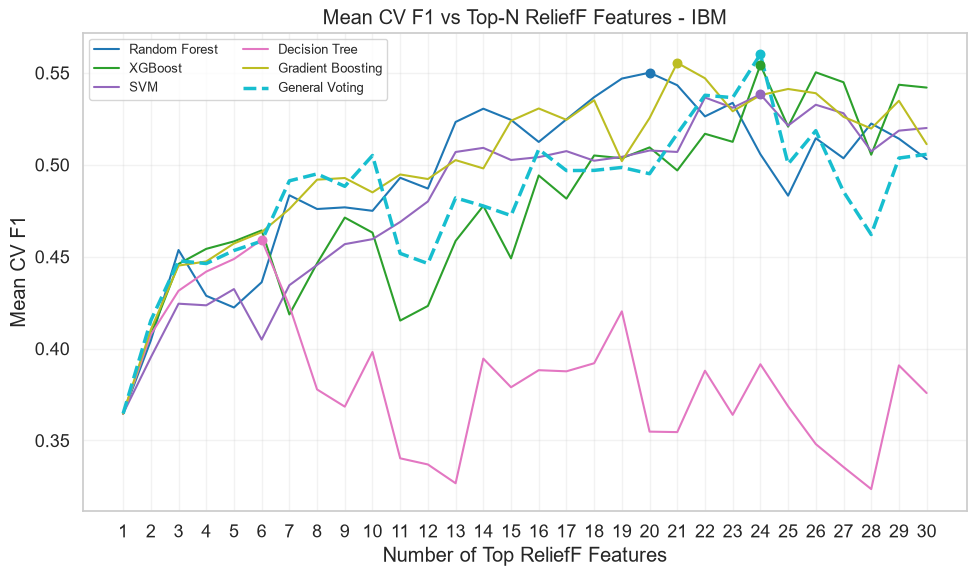

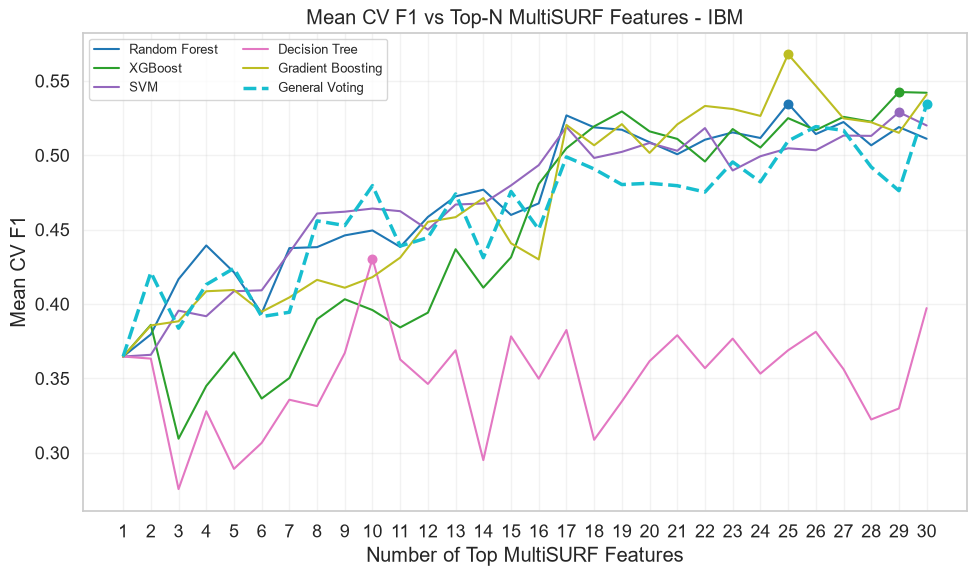

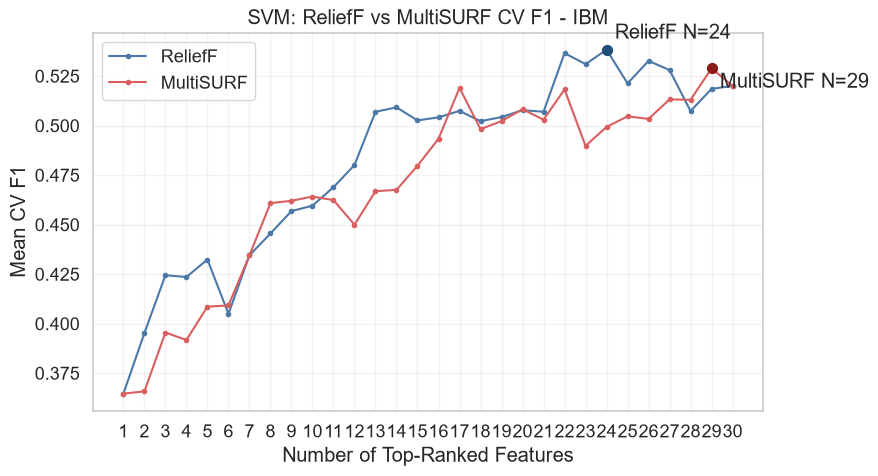

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Compare feature-count curves for the five individual classifiers and the
# paper's general soft-voting classifier. Other voting ablations remain in tables.
focus_model_name = "SVM"
n_values = np.arange(1, max_n + 1)
comparison_model_names = list(base_model_templates.keys()) + ["General Voting"]
missing_curve_models = [
    name for name in comparison_model_names
    if name not in scores["relief"] or name not in scores["multi"]
]
if missing_curve_models:
    raise KeyError(f"Missing Top-N CV curves for: {missing_curve_models}")

focus_relief_cv = np.asarray(scores["relief"][focus_model_name], dtype=float)
focus_multi_cv = np.asarray(scores["multi"][focus_model_name], dtype=float)
focus_relief_n = best_feature_counts["ReliefF"][focus_model_name]
focus_multi_n = best_feature_counts["MultiSURF"][focus_model_name]

fs_cv_comparison = pd.DataFrame({
    "Feature Selection": ["ReliefF", "MultiSURF"],
    "Model": [focus_model_name, focus_model_name],
    "Optimal Features": [focus_relief_n, focus_multi_n],
    "Best Mean CV F1": [focus_relief_cv[focus_relief_n - 1], focus_multi_cv[focus_multi_n - 1]],
})
print(f"Focused feature-selection comparison - {focus_model_name} - IBM")
display(fs_cv_comparison.round(4))

def plot_top_n_curves(score_key, selector_name):
    plt.figure(figsize=(10, 6))
    colours = plt.cm.tab10(np.linspace(0, 1, len(comparison_model_names)))
    for colour, model_name in zip(colours, comparison_model_names):
        curve = np.asarray(scores[score_key][model_name], dtype=float)
        optimal_n = best_feature_counts[selector_name][model_name]
        is_voting = model_name == "General Voting"
        plt.plot(
            n_values, curve,
            label=model_name,
            color=colour,
            linewidth=2.5 if is_voting else 1.5,
            linestyle="--" if is_voting else "-",
        )
        plt.scatter(optimal_n, curve[optimal_n - 1], color=colour, s=38, zorder=3)
    plt.xlabel(f"Number of Top {selector_name} Features")
    plt.ylabel("Mean CV F1")
    plt.title(f"Mean CV F1 vs Top-N {selector_name} Features - IBM")
    plt.xticks(n_values)
    plt.legend(ncol=2, fontsize=9)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# Figure 1: all individual models and General Voting using ReliefF rankings.
plot_top_n_curves("relief", "ReliefF")

# Figure 2: all individual models and General Voting using MultiSURF rankings.
plot_top_n_curves("multi", "MultiSURF")

# Figure 3: matched selector comparison for the dataset's selected best model.
plt.figure(figsize=(9, 5))
plt.plot(n_values, focus_relief_cv, marker="o", markersize=3, label="ReliefF", color="#4C78A8")
plt.plot(n_values, focus_multi_cv, marker="o", markersize=3, label="MultiSURF", color="#D95F5F")
plt.scatter(focus_relief_n, focus_relief_cv[focus_relief_n - 1], color="#1F4E79", s=50, zorder=3)
plt.scatter(focus_multi_n, focus_multi_cv[focus_multi_n - 1], color="#8B1A1A", s=50, zorder=3)
plt.annotate(f"ReliefF N={focus_relief_n}", (focus_relief_n, focus_relief_cv[focus_relief_n - 1]),
             xytext=(6, 8), textcoords="offset points")
plt.annotate(f"MultiSURF N={focus_multi_n}", (focus_multi_n, focus_multi_cv[focus_multi_n - 1]),
             xytext=(6, -14), textcoords="offset points")
plt.xlabel("Number of Top-Ranked Features")
plt.ylabel("Mean CV F1")
plt.title(f"{focus_model_name}: ReliefF vs MultiSURF CV F1 - IBM")
plt.xticks(n_values)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [21]:
print("Voting classifier feature-count comparison:")
display(voting_feature_summary.sort_values(["Feature Selection", "Best CV F1"], ascending=[True, False]).round(4))


Voting classifier feature-count comparison:


,Feature Selection,Model,Optimal Features,Best CV F1
13,MultiSURF,Voting GB + XGBoost + SVM,29,0.5724
12,MultiSURF,Voting GB + SVM,25,0.5627
11,MultiSURF,Voting RF + XGBoost,30,0.5600
14,MultiSURF,Voting RF + GB + XGBoost,25,0.5577
15,MultiSURF,Voting All Five,30,0.5570
10,MultiSURF,Voting GB + XGBoost (equal weights),26,0.5568
9,MultiSURF,Hard Voting,25,0.5563
8,MultiSURF,General Voting,30,0.5341
5,ReliefF,Voting GB + XGBoost + SVM,24,0.5847
4,ReliefF,Voting GB + SVM,26,0.5847


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("="*60)
print("FINAL HOLDOUT TEST EVALUATION - IBM")
print("="*60)

rankings = {"ReliefF": relieff_sorted, "MultiSURF": multisurf_sorted}
model_templates = {**base_model_templates, **voting_models}
model_sizes = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in model_templates
    }
    for selector_name in rankings
}
cv_arrays = {
    "ReliefF": scores["relief"],
    "MultiSURF": scores["multi"],
}


test_results = []
final_models = {}
for selector_name, ranking in rankings.items():
    for model_name, estimator in model_templates.items():
        n = model_sizes[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        model_pipeline = build_model_pipeline(clone(estimator))
        model_pipeline.fit(X_train_raw_model.loc[:, selected_features], y_train)
        X_eval = X_test_raw_model.loc[:, selected_features]
        y_pred = model_pipeline.predict(X_eval)
        y_score = positive_scores(model_pipeline, X_eval)
        test_results.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Features": n,
            "CV F1": cv_arrays[selector_name][model_name][n - 1],
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_score),
            "PR AUC": average_precision_score(y_test, y_score),
        })
        final_models[(selector_name, model_name)] = (model_pipeline, selected_features)

test_results = pd.DataFrame(test_results)
display(test_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))


# Focused holdout comparison for the same classifier under both selectors.
focus_feature_selection_results = test_results[test_results["Model"] == "SVM"].copy()
print("Focused ReliefF versus MultiSURF holdout comparison - SVM:")
display(focus_feature_selection_results[[
    "Feature Selection", "Model", "Features", "CV F1", "F1", "Recall",
    "Precision", "Accuracy", "ROC AUC", "PR AUC"
]].sort_values("Feature Selection").round(4))

voting_results = test_results[test_results["Model"].isin(voting_models)].copy()
print("Voting classifier comparison (each model uses its own optimized feature count):")
display(voting_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

# Run-to-run variance for every voting classifier at its own optimized feature count.
variance_feature_counts = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in voting_models
    }
    for selector_name in rankings
}
optimized_variance_rows = []
for selector_name, ranking in rankings.items():
    for model_name, estimator in voting_models.items():
        n = variance_feature_counts[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        variance_frame = run_to_run_variance(
            estimator,
            X_train_raw_model.loc[:, selected_features],
            y_train,
            model_name,
        )
        variance_frame.insert(0, "Feature Selection", selector_name)
        variance_frame.insert(2, "Features", n)
        optimized_variance_rows.extend(variance_frame.to_dict("records"))
optimized_run_variance = pd.DataFrame(optimized_variance_rows)
print("Run-to-run stability for voting classifiers at their own optimized feature counts:")
display(optimized_run_variance.sort_values(["Feature Selection", "Model", "Seed"]).round(4))
run_variance_summary = (
    optimized_run_variance.groupby(["Feature Selection", "Model"])["Mean CV F1"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "Run Mean CV F1", "std": "Run SD"})
)
display(run_variance_summary.round(4))

from sklearn.dummy import DummyClassifier
majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train_raw_model, y_train)
majority_pred = majority.predict(X_test_raw_model)
print("\nMajority-class baseline:")
print(f"  Accuracy={accuracy_score(y_test, majority_pred):.4f}, F1={f1_score(y_test, majority_pred, zero_division=0):.4f}, Recall={recall_score(y_test, majority_pred, zero_division=0):.4f}")


FINAL HOLDOUT TEST EVALUATION - IBM


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
15,MultiSURF,SVM,29,0.5289,0.8129,0.4412,0.6383,0.5217,0.8070,0.5158
22,MultiSURF,Voting GB + SVM,25,0.5627,0.8333,0.4800,0.5106,0.4948,0.8145,0.5299
20,MultiSURF,Voting GB + XGBoost (equal weights),26,0.5568,0.8707,0.6667,0.3830,0.4865,0.8134,0.5840
23,MultiSURF,Voting GB + XGBoost + SVM,29,0.5724,0.8571,0.5758,0.4043,0.4750,0.8257,0.5657
24,MultiSURF,Voting RF + GB + XGBoost,25,0.5577,0.8639,0.6207,0.3830,0.4737,0.8053,0.5168
19,MultiSURF,Hard Voting,25,0.5563,0.8605,0.6000,0.3830,0.4675,0.6672,0.3284
18,MultiSURF,General Voting,30,0.5341,0.8401,0.5000,0.4255,0.4598,0.7743,0.5064
14,MultiSURF,XGBoost,29,0.5425,0.8639,0.6296,0.3617,0.4595,0.8153,0.5749
17,MultiSURF,Gradient Boosting,25,0.5678,0.8571,0.5862,0.3617,0.4474,0.7963,0.5038
13,MultiSURF,Random Forest,25,0.5347,0.8061,0.4000,0.4255,0.4124,0.7783,0.4269


Focused ReliefF versus MultiSURF holdout comparison - SVM:


,Feature Selection,Model,Features,CV F1,F1,Recall,Precision,Accuracy,ROC AUC,PR AUC
15,MultiSURF,SVM,29,0.5289,0.5217,0.6383,0.4412,0.8129,0.8070,0.5158
2,ReliefF,SVM,24,0.5383,0.4717,0.5319,0.4237,0.8095,0.8008,0.5188


Voting classifier comparison (each model uses its own optimized feature count):


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
22,MultiSURF,Voting GB + SVM,25,0.5627,0.8333,0.4800,0.5106,0.4948,0.8145,0.5299
20,MultiSURF,Voting GB + XGBoost (equal weights),26,0.5568,0.8707,0.6667,0.3830,0.4865,0.8134,0.5840
23,MultiSURF,Voting GB + XGBoost + SVM,29,0.5724,0.8571,0.5758,0.4043,0.4750,0.8257,0.5657
24,MultiSURF,Voting RF + GB + XGBoost,25,0.5577,0.8639,0.6207,0.3830,0.4737,0.8053,0.5168
19,MultiSURF,Hard Voting,25,0.5563,0.8605,0.6000,0.3830,0.4675,0.6672,0.3284
18,MultiSURF,General Voting,30,0.5341,0.8401,0.5000,0.4255,0.4598,0.7743,0.5064
25,MultiSURF,Voting All Five,30,0.5570,0.8333,0.4706,0.3404,0.3951,0.7833,0.5061
21,MultiSURF,Voting RF + XGBoost,30,0.5600,0.8435,0.5185,0.2979,0.3784,0.7906,0.5078
9,ReliefF,Voting GB + SVM,26,0.5847,0.8299,0.4681,0.4681,0.4681,0.8113,0.5203
10,ReliefF,Voting GB + XGBoost + SVM,24,0.5847,0.8503,0.5484,0.3617,0.4359,0.8098,0.5303


Run-to-run stability for voting classifiers at their own optimized feature counts:


,Feature Selection,Model,Features,Seed,Mean CV F1,Fold SD
24,MultiSURF,General Voting,30,42,0.5341,0.0550
25,MultiSURF,General Voting,30,43,0.5309,0.0893
26,MultiSURF,General Voting,30,44,0.5168,0.0630
27,MultiSURF,Hard Voting,25,42,0.5563,0.0696
28,MultiSURF,Hard Voting,25,43,0.5377,0.0560
29,MultiSURF,Hard Voting,25,44,0.5237,0.1233
45,MultiSURF,Voting All Five,30,42,0.5570,0.0387
46,MultiSURF,Voting All Five,30,43,0.5360,0.0956
47,MultiSURF,Voting All Five,30,44,0.5281,0.0802
36,MultiSURF,Voting GB + SVM,25,42,0.5627,0.0486


Run Mean CV F1  Run SD
Feature Selection Model                                                      
MultiSURF         General Voting                               0.5273  0.0092
                  Hard Voting                                  0.5393  0.0163
                  Voting All Five                              0.5403  0.0149
                  Voting GB + SVM                              0.5588  0.0064
                  Voting GB + XGBoost (equal weights)          0.5310  0.0228
                  Voting GB + XGBoost + SVM                    0.5620  0.0119
                  Voting RF + GB + XGBoost                     0.5555  0.0020
                  Voting RF + XGBoost                          0.5330  0.0244
ReliefF           General Voting                               0.5551  0.0064
                  Hard Voting                                  0.5551  0.0156
                  Voting All Five                              0.5702  0.0078
                  Voting GB + SVM                              0.5673  0.0151
                  Voting GB + XGBoost (equal weights)          0.5504  0.0135
                  Voting GB + XGBoost + SVM                    0.5685  0.0148
                  Voting RF + GB + XGBoost                     0.5586  0.0107
                  Voting RF + XGBoost                          0.5529  0.0211


Majority-class baseline:
  Accuracy=0.8401, F1=0.0000, Recall=0.0000


SHAP ANALYSIS - MultiSURF + SVM - IBM


100%|██████████| 100/100 [05:56<00:00,  3.57s/it]


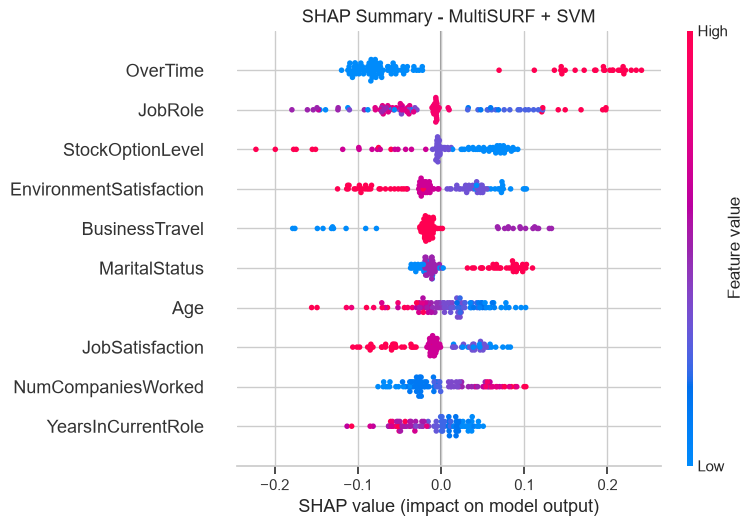

Dependence plots: ['Age', 'JobLevel', 'TotalWorkingYears']


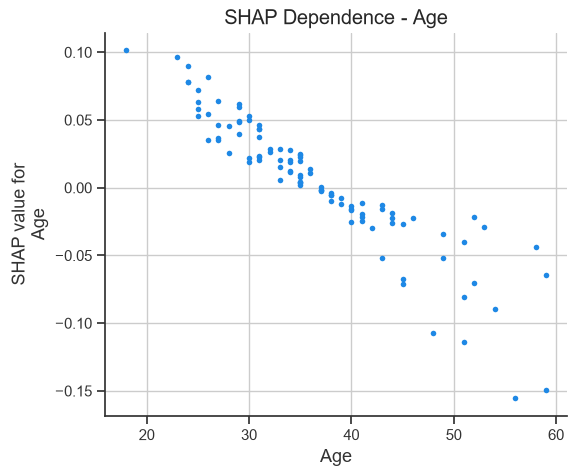

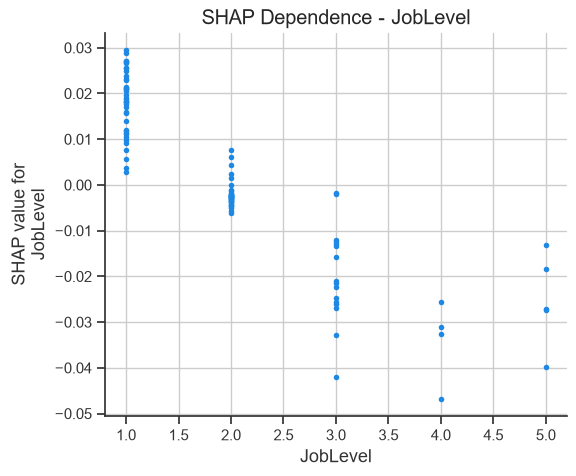

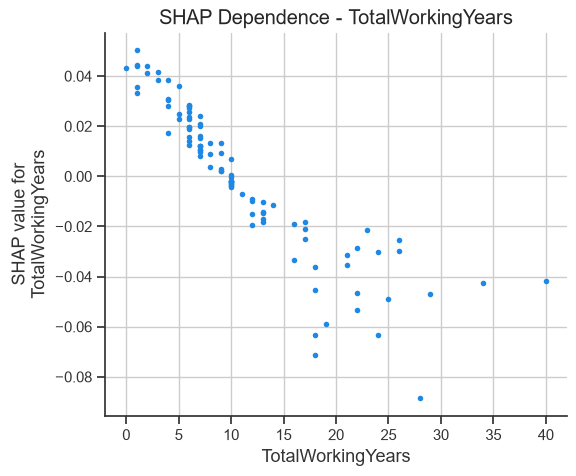

Local explanation: held-out row 1061, actual=0, predicted=0, leaver probability=0.4185, SHAP base (leaver probability)=0.3426


,Feature,Value,SHAP value
0,JobRole,8,0.1943
1,BusinessTravel,0,-0.1782
2,EnvironmentSatisfaction,4,-0.1116
3,OverTime,0,-0.0944
4,Age,24,0.0898
5,JobSatisfaction,2,0.0487
6,YearsWithCurrManager,0,0.0457
7,TotalWorkingYears,1,0.0445
8,YearsInCurrentRole,0,0.0434
9,Gender,0,-0.0390


,Feature,SMOTE endpoint effect,No-SMOTE endpoint effect,Direction agrees
0,Age,-0.1196,-0.0873,True
1,JobLevel,-0.0730,-0.0192,True
2,TotalWorkingYears,-0.0983,-0.0745,True
3,YearsAtCompany,-0.0641,-0.0432,True
4,YearsInCurrentRole,-0.0985,-0.0537,True
5,YearsSinceLastPromotion,0.0337,0.0366,True
6,YearsWithCurrManager,-0.0968,-0.0513,True


Endpoint effects are sensitivity checks, not causal or cultural effects.


In [23]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone

shap_selector_name = "MultiSURF"
shap_model_name = "SVM"
shap_value_scale = "leaver probability"
shap_key = (shap_selector_name, shap_model_name)
print("="*60)
print(f"SHAP ANALYSIS - {shap_selector_name} + {shap_model_name} - IBM")
print("="*60)

if "final_models" not in globals() or shap_key not in final_models:
    raise RuntimeError("Run the final holdout-evaluation cell before this SHAP cell.")
final_pipeline, shap_features = final_models[shap_key]
assert len(shap_features) == best_feature_counts[shap_selector_name][shap_model_name]

shap_smoke = os.environ.get("ATTRITION_SHAP_SMOKE", "0") == "1"
background_size = 10 if shap_smoke else 50
explanation_size = 4 if shap_smoke else 100
coalition_budget = 32 if shap_smoke else 500
background = X_train_raw_model.loc[:, shap_features].sample(
    n=min(background_size, len(X_train_raw_model)), random_state=SEED
)
X_shap_test = X_test_raw_model.loc[:, shap_features].iloc[:explanation_size].copy()

def shap_predict(values):
    frame = values if isinstance(values, pd.DataFrame) else pd.DataFrame(values, columns=shap_features)
    return final_pipeline.predict_proba(frame.loc[:, shap_features])[:, 1]

np.random.seed(SEED)
explainer = shap.KernelExplainer(shap_predict, background)
shap_values = explainer.shap_values(X_shap_test, nsamples=coalition_budget, l1_reg=0.0)
if isinstance(shap_values, list):
    shap_values = shap_values[-1]
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]
local_base_value = float(np.asarray(explainer.expected_value).reshape(-1)[-1])

# Global importance summary.
shap.summary_plot(
    shap_values,
    X_shap_test,
    feature_names=shap_features,
    max_display=10,
    show=False,
)
plt.title(f"SHAP Summary - {shap_selector_name} + {shap_model_name}", fontsize=13)
plt.tight_layout()
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_features).sort_values(ascending=False)
seniority_candidates = ['Age', 'JobLevel', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
dependence_features = [f for f in seniority_candidates if f in shap_features]
dependence_features += [f for f in mean_abs_shap.index if f not in dependence_features]
dependence_features = dependence_features[:3]
print("Dependence plots:", dependence_features)
for feature in dependence_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap_test,
        feature_names=shap_features,
        interaction_index=None,
        show=False,
    )
    plt.title(f"SHAP Dependence - {feature}")
    plt.tight_layout()
    plt.show()

# A fixed local case is used instead of selecting a favourable observation.
local_index = 0
local_row_label = X_shap_test.index[local_index]
local_feature_order = np.argsort(np.abs(shap_values[local_index]))[::-1][:10]
local_prediction = final_pipeline.predict_proba(X_shap_test.iloc[[local_index]])[0, 1]
local_class = int(final_pipeline.predict(X_shap_test.iloc[[local_index]])[0])
local_actual = int(y_test.loc[local_row_label])
local_explanation = pd.DataFrame({
    "Feature": [shap_features[i] for i in local_feature_order],
    "Value": [X_shap_test.iloc[local_index, i] for i in local_feature_order],
    "SHAP value": [shap_values[local_index, i] for i in local_feature_order],
})
print(
    f"Local explanation: held-out row {local_row_label}, actual={local_actual}, "
    f"predicted={local_class}, leaver probability={local_prediction:.4f}, "
    f"SHAP base ({shap_value_scale})={local_base_value:.4f}"
)
display(local_explanation.round(4))

# Sensitivity check: same classifier settings and features, changing SMOTE only.
seniority_features = [feature for feature in seniority_candidates if feature in shap_features]
if seniority_features:
    no_smote_pipeline = build_model_pipeline(clone(base_model_templates[shap_model_name]), use_smote=False)
    no_smote_pipeline.fit(X_train_raw_model.loc[:, shap_features], y_train)
    artifact_rows = []
    for feature in seniority_features:
        low_value, high_value = X_train_raw_model[feature].quantile([0.10, 0.90])
        low_frame = X_shap_test.copy()
        high_frame = X_shap_test.copy()
        low_frame[feature] = low_value
        high_frame[feature] = high_value
        smote_effect = np.mean(
            final_pipeline.predict_proba(high_frame)[:, 1]
            - final_pipeline.predict_proba(low_frame)[:, 1]
        )
        no_smote_effect = np.mean(
            no_smote_pipeline.predict_proba(high_frame)[:, 1]
            - no_smote_pipeline.predict_proba(low_frame)[:, 1]
        )
        artifact_rows.append({
            "Feature": feature,
            "SMOTE endpoint effect": smote_effect,
            "No-SMOTE endpoint effect": no_smote_effect,
            "Direction agrees": np.sign(smote_effect) == np.sign(no_smote_effect),
        })
    seniority_check = pd.DataFrame(artifact_rows)
    display(seniority_check.round(4))
    print("Endpoint effects are sensitivity checks, not causal or cultural effects.")
else:
    print("No predefined seniority feature is present in this selected subset.")


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison_model_name = "Voting RF + GB + XGBoost"
selector_name = "MultiSURF"
selected_n = best_feature_counts[selector_name][comparison_model_name]
selected_features = [feature for feature, _ in multisurf_sorted[:selected_n]]

comparison_rows = []
for mode, use_smote in [("Without SMOTE", False), ("With SMOTE", True)]:
    comparison_model = build_model_pipeline(clone(voting_models[comparison_model_name]), use_smote=use_smote)
    comparison_model.fit(X_train_raw_model.loc[:, selected_features], y_train)
    predictions = comparison_model.predict(X_test_raw_model.loc[:, selected_features])
    comparison_rows.append({
        "Dataset": "IBM",
        "Model": comparison_model_name,
        "Feature Selection": selector_name,
        "Features": selected_n,
        "Mode": mode,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
    })

smote_comparison = pd.DataFrame(comparison_rows)
display(smote_comparison.round(4))


,Dataset,Model,Feature Selection,Features,Mode,Accuracy,Precision,Recall,F1
0,IBM,Voting RF + GB + XGBoost,MultiSURF,25,Without SMOTE,0.8537,0.6429,0.1915,0.2951
1,IBM,Voting RF + GB + XGBoost,MultiSURF,25,With SMOTE,0.8639,0.6207,0.3830,0.4737
